# Implementación de Transformers para Procesamiento de Lenguaje Natural (NLP)

### Objetivo
En esta evaluación implementamos un modelo **Transformer encoder-decoder** para una tarea de NLP generativa sobre el corpus **DailyDialog**: dado el turno anterior de una conversación, el modelo debe **generar la respuesta** del siguiente hablante. Se evalúa con métricas específicas de generación (BLEU, ROUGE) y con la perplejidad de validación.

### Resumen de la solución

| Elemento | Decisión |
|---|---|
| Tarea | Generación de respuesta: `turno anterior -> turno actual` (76 052 pares en train). |
| Tokenización | Separación por espacios + minúsculas. El corpus ya trae la puntuación separada (`"hola , qué tal ?"`), así que no hace falta un tokenizador agresivo. |
| Vocabulario | ~13 400 tokens (`min_freq = 2`) + 4 tokens especiales (`<pad>`, `<sos>`, `<eos>`, `<unk>`). |
| Longitud máxima | 32 tokens para origen y destino (cubre ~94 % de los turnos sin truncar). |
| Modelo | Transformer encoder-decoder: `d_model=128`, 4 cabezas, FFN 512, 2 capas en encoder y 2 en decoder, pre-LN y dropout 0.1. |
| Entrenamiento | Adam con *warmup* + decaimiento inverso a la raíz, batch 64, early stopping sobre `val_loss`. |
| Evaluación | Perplejidad, BLEU (corpus y frase) y ROUGE-1/2/L sobre el split de test. |
| Ajuste | Búsqueda reducida sobre `num_heads`, `ff_dim` y `num_layers`. |

> **Nota:** el notebook está listo para ejecutarse directamente en Google Colab o en local. Si los CSV no están presentes, se busca y descomprime el ZIP adjunto; si tampoco está, Colab pide subirlo. La primera celda instala las dos librerías de métricas que no vienen por defecto.

## 1. Carga y Exploración del Dataset: DailyDialog

El dataset se entrega como tres CSV (`train.csv`, `validation.csv`, `test.csv`) con tres columnas:

* `dialog`: representación textual de un array de NumPy con los turnos de la conversación.
* `act`: etiqueta del acto de diálogo de cada turno (1–4).
* `emotion`: emoción de cada turno (0–6).

La columna `dialog` **no es un CSV normal**: es el `repr` de un array de NumPy (`['a' 'b' 'c']`), donde los elementos se separan por saltos de línea o espacios y pueden usar comillas simples o dobles. `ast.literal_eval` directo concatenaría los strings adyacentes, así que la parseamos con el **tokenizador de Python**, que identifica cada literal de string de forma robusta. Verificamos además que el número de turnos coincide con el de etiquetas `act`/`emotion` en las 11 118 conversaciones de train.

In [24]:
import os
import io
import re
import ast
import time
import random
import tokenize
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU disponible:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU disponible: False


### Modo de ejecución (GPU / CPU)

El notebook detecta si hay GPU. **Con GPU** se ejecuta la configuración completa (8 epochs sobre los 76 052 pares, evaluación sobre todo el test y búsqueda con 20 000 pares). **Sin GPU** (modo CPU) se reduce el cómputo para que termine en un tiempo razonable: 1 epoch, evaluación sobre 1 000 ejemplos de test y búsqueda con 5 000 pares. Si existe un *checkpoint* `transformer_dailydialog.weights.h5` de una corrida anterior, en modo CPU se cargan esos pesos en vez de reentrenar. Las limitaciones derivadas de este modo se discuten en las conclusiones.

In [25]:
GPU = len(tf.config.list_physical_devices("GPU")) > 0
MODO_RAPIDO = not GPU
print("Modo:", "GPU (configuración completa)" if GPU else "CPU (configuración reducida)")

Modo: CPU (configuración reducida)


In [26]:
!pip install -q rouge-score nltk

### 1.1. Localización de los datos

Se buscan los CSV en las rutas habituales (misma carpeta, `Downloads`, `/content`). La búsqueda es recursiva (incluye subcarpetas y Drive montado) y descomprime automáticamente el ZIP. Si no encuentra nada, Colab abre un diálogo para subir el archivo.

In [27]:
import glob
import zipfile

SEARCH_ROOTS = [".", "/content", "/content/drive/MyDrive", os.path.expanduser("~/Downloads")]
NEEDED = {"train.csv", "validation.csv", "test.csv"}

def find_data_dir():
    """Busca recursivamente una carpeta que contenga los 3 CSV."""
    for root in SEARCH_ROOTS:
        if not os.path.isdir(root):
            continue
        for d, _, files in os.walk(root):
            if NEEDED <= set(files):
                return d
    return None

def extract_zips():
    """Descomprime cualquier ZIP que contenga train.csv (en cualquier subcarpeta)."""
    for root in SEARCH_ROOTS:
        for zpath in glob.glob(os.path.join(root, "**", "*.zip"), recursive=True):
            try:
                with zipfile.ZipFile(zpath) as zf:
                    if any(n.endswith("train.csv") for n in zf.namelist()):
                        out = os.path.splitext(zpath)[0]
                        zf.extractall(out)
                        print("ZIP descomprimido:", zpath, "->", out)
            except zipfile.BadZipFile:
                pass

DATA_DIR = find_data_dir()
if DATA_DIR is None:
    extract_zips()
    DATA_DIR = find_data_dir()

if DATA_DIR is None:
    try:
        from google.colab import files
        print("No se encontraron los CSV. Sube dataset_3ra_evaluacion_1.zip (o los 3 CSV):")
        files.upload()
        extract_zips()
        DATA_DIR = find_data_dir()
    except ImportError:
        pass

if DATA_DIR is None:
    raise FileNotFoundError(
        "No se encontraron train.csv, validation.csv y test.csv. "
        "Sube dataset_3ra_evaluacion_1.zip a /content y vuelve a ejecutar esta celda."
    )

CSV_PATHS = {split: os.path.join(DATA_DIR, f"{split}.csv") for split in ["train", "validation", "test"]}
USE_TFDS = False  # DailyDialog no está en tensorflow_datasets: siempre se usan los CSV
print("CSV encontrados en:", DATA_DIR)

CSV encontrados en: ./dataset 3ra evaluacion (1)


### 1.2. Parseo robusto de las columnas

`parse_dialog` usa `tokenize` para extraer **cada** literal de string del `repr` del array; `parse_ints` extrae los enteros de `act`/`emotion`. Después comprobamos la coherencia de longitudes.

In [28]:
def parse_dialog(raw):
    """Extrae la lista de turnos del repr de un array de NumPy.

    Ejemplo: "['hola .'\\n ' ¿ qué tal ? ']" -> ['hola .', ' ¿ qué tal ? ']
    """
    tokens = []
    for tok in tokenize.generate_tokens(io.StringIO(raw.strip()).readline):
        if tok.type == tokenize.STRING:
            tokens.append(ast.literal_eval(tok.string))
    return [t.strip() for t in tokens]

def parse_ints(raw):
    """Extrae los enteros del repr de un array de NumPy: '[3 2 4]' -> [3, 2, 4]."""
    return [int(x) for x in re.findall(r"\d+", raw)]

def load_split(name):
    """Devuelve (dialogs, acts, emotions) para un split."""
    if not USE_TFDS:
        df = pd.read_csv(CSV_PATHS[name])
        dialogs = [parse_dialog(s) for s in df["dialog"]]
        acts = [parse_ints(s) for s in df["act"]]
        emotions = [parse_ints(s) for s in df["emotion"]]
        return dialogs, acts, emotions

    raise RuntimeError("No hay CSV disponibles")

train_dialogs, train_acts, train_emotions = load_split("train")
val_dialogs, _, _ = load_split("validation")
test_dialogs, _, _ = load_split("test")

print("Conversaciones -> train: {:,} | validation: {:,} | test: {:,}".format(
    len(train_dialogs), len(val_dialogs), len(test_dialogs)))

Conversaciones -> train: 11,118 | validation: 1,000 | test: 1,000


### 1.3. Verificación de la integridad y estadísticas básicas

In [29]:
mismatches = sum(
    1 for d, a, e in zip(train_dialogs, train_acts, train_emotions)
    if not (len(d) == len(a) == len(e))
)
print("Conversaciones con turnos/etiquetas desalineados:", mismatches)

n_dialogs = len(train_dialogs)
n_turns = sum(len(d) for d in train_dialogs)
turn_lens = [len(t.split()) for d in train_dialogs for t in d]

print("Turnos totales (train): {:,}".format(n_turns))
print("Turnos por conversación: media {:.1f}, mediana {:.1f}, máx {}".format(
    np.mean([len(d) for d in train_dialogs]),
    np.median([len(d) for d in train_dialogs]),
    max(len(d) for d in train_dialogs)))
print("Palabras por turno: media {:.1f}, mediana {:.1f}, p95 {:.0f}, máx {}".format(
    np.mean(turn_lens), np.median(turn_lens), np.percentile(turn_lens, 95), max(turn_lens)))
print()
print("Ejemplo de conversación (primeros 4 turnos):")
for i, t in enumerate(train_dialogs[0][:4]):
    print(f"  [{i}] {t}")

Conversaciones con turnos/etiquetas desalineados: 0
Turnos totales (train): 87,170
Turnos por conversación: media 7.8, mediana 7.0, máx 35
Palabras por turno: media 13.6, mediana 11.0, p95 33, máx 278

Ejemplo de conversación (primeros 4 turnos):
  [0] Say , Jim , how about going for a few beers after dinner ?
  [1] You know that is tempting but is really not good for our fitness .
  [2] What do you mean ? It will help us to relax .
  [3] Do you really think so ? I don't . It will just make us fat and act silly . Remember last time ?


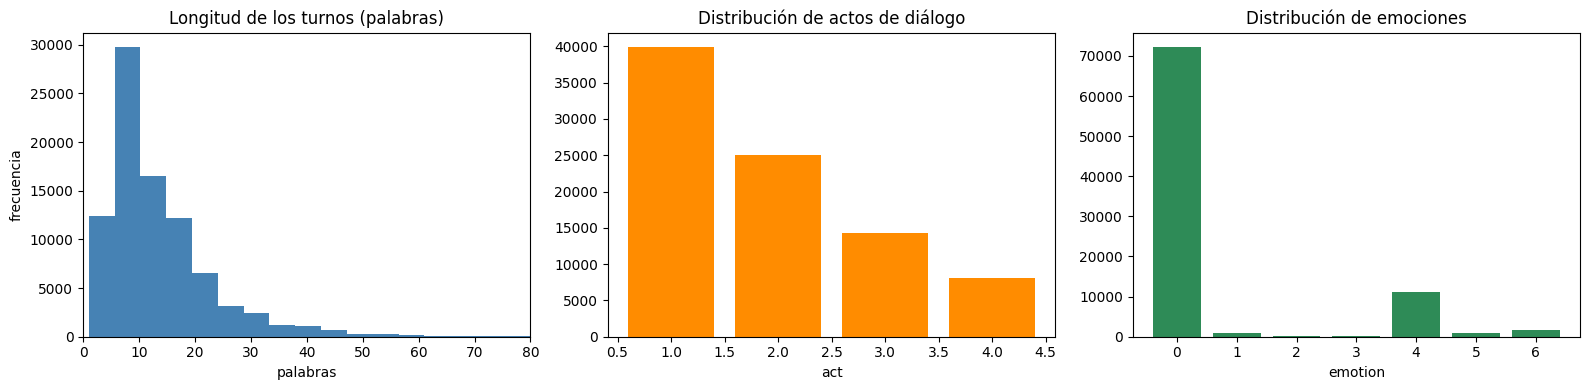

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(turn_lens, bins=60, color="steelblue")
axes[0].set_title("Longitud de los turnos (palabras)")
axes[0].set_xlabel("palabras")
axes[0].set_ylabel("frecuencia")
axes[0].set_xlim(0, 80)

acts = [a for row in train_acts for a in row]
emotions = [e for row in train_emotions for e in row]
axes[1].bar(*np.unique(acts, return_counts=True), color="darkorange")
axes[1].set_title("Distribución de actos de diálogo")
axes[1].set_xlabel("act")

axes[2].bar(*np.unique(emotions, return_counts=True), color="seagreen")
axes[2].set_title("Distribución de emociones")
axes[2].set_xlabel("emotion")

plt.tight_layout()
plt.show()

In [31]:
all_tokens = [w for d in train_dialogs for t in d for w in t.lower().split()]
counter = collections.Counter(all_tokens)

print("Tokens totales: {:,}".format(len(all_tokens)))
print("Tipos distintos: {:,}".format(len(counter)))
for mf in [1, 2, 3, 5]:
    print("  min_freq={}: {:,} tokens de vocabulario".format(
        mf, sum(1 for c in counter.values() if c >= mf)))
print()
print("20 tokens más frecuentes:", counter.most_common(20))

Tokens totales: 1,186,046
Tipos distintos: 22,075
  min_freq=1: 22,075 tokens de vocabulario
  min_freq=2: 13,371 tokens de vocabulario
  min_freq=3: 9,846 tokens de vocabulario
  min_freq=5: 7,083 tokens de vocabulario

20 tokens más frecuentes: [('.', 98110), (',', 46009), ('you', 38840), ('i', 37486), ('?', 33103), ('the', 32224), ('to', 27759), ('a', 23490), ('it', 15980), ('and', 14252), ('is', 13764), ('’', 12084), ('of', 11645), ('in', 11089), ('that', 10933), ('have', 10863), ('for', 10535), ('do', 9212), ('are', 8488), ('!', 7894)]


**Observaciones del EDA.** Los turnos son cortos (mediana 11 palabras, p95 = 33), lo que permite fijar `MAX_LEN = 32` perdiendo muy poca información. El vocabulario es muy disperso: ~22 000 tipos, de los que ~40 % aparecen una sola vez. Por eso usamos `min_freq = 2` y un token `<unk>`: reduce el vocabulario a ~13 400 y evita que la capa de salida se llene de palabras imposibles de aprender. Los actos y emociones están desbalanceados y no los usamos como entrada (la tarea es generar la respuesta, no clasificarla), pero se conservan en el análisis.

## 2. Preprocesamiento y construcción del corpus supervisado

**Formulación de la tarea.** Para cada conversación `[t0, t1, ..., tn]` generamos los pares `(t_{i-1} -> t_i)`. El turno anterior actúa como contexto y el modelo aprende a producir la respuesta. Es la formulación estándar *one-turn context* para respuesta de diálogo: aporta contexto real y mantiene las secuencias cortas (un contexto multiturno multiplicaría la longitud y el coste de cómputo sin que un modelo pequeño pueda explotarlo).

**Normalización.** Pasamos todo a minúsculas. El corpus ya está tokenizado "a la PTB" (puntuación separada por espacios), así que `split()` es un tokenizador adecuado y reversible.

In [32]:
def build_pairs(dialogs):
    """Devuelve pares (turno_anterior, turno_actual) en minúsculas."""
    pairs = []
    for d in dialogs:
        for prev, cur in zip(d[:-1], d[1:]):
            pairs.append((prev.lower(), cur.lower()))
    return pairs

train_pairs = build_pairs(train_dialogs)
val_pairs = build_pairs(val_dialogs)
test_pairs = build_pairs(test_dialogs)

print("Pares train: {:,}".format(len(train_pairs)))
print("Pares validation: {:,}".format(len(val_pairs)))
print("Pares test: {:,}".format(len(test_pairs)))
print()
print("Ejemplo:")
print("  contexto :", train_pairs[0][0])
print("  respuesta:", train_pairs[0][1])

Pares train: 76,052
Pares validation: 7,069
Pares test: 6,740

Ejemplo:
  contexto : say , jim , how about going for a few beers after dinner ?
  respuesta: you know that is tempting but is really not good for our fitness .


### 2.1. Vocabulario

Reservamos cuatro identificadores fijos:

* `<pad>` = 0 -> relleno; se ignora en la loss y en la atención.
* `<sos>` = 1 -> inicio de la respuesta (solo en la entrada del decoder).
* `<eos>` = 2 -> fin de la respuesta.
* `<unk>` = 3 -> palabras no vistas.

El resto de tokens se ordenan por frecuencia, lo que hace el vocabulario determinista.

In [33]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3
MIN_FREQ = 2
MAX_LEN = 32

counter = collections.Counter(
    w for d in train_dialogs for t in d for w in t.lower().split()
)
vocab = ["<pad>", "<sos>", "<eos>", "<unk>"] + [
    w for w, c in counter.most_common() if c >= MIN_FREQ
]
word2id = {w: i for i, w in enumerate(vocab)}
id2word = {i: w for w, i in word2id.items()}

VOCAB_SIZE = len(vocab)
print("Tamaño del vocabulario:", VOCAB_SIZE)
print("Cobertura en train: {:.2f} % de los tokens".format(
    100 * sum(c for w, c in counter.items() if w in word2id) / sum(counter.values())))

Tamaño del vocabulario: 13375
Cobertura en train: 99.27 % de los tokens


### 2.2. Codificación a tensores

* **Origen**: tokens + `<eos>` truncados a `MAX_LEN` y rellenados con `<pad>`.
* **Destino**: `<sos>` + tokens + `<eos>`, también con longitud fija `MAX_LEN`.
* El decoder recibe `destino[:-1]` y debe predecir `destino[1:]` (desplazamiento de un token), que es el *teacher forcing* estándar.

In [34]:
def encode_src(text):
    ids = [word2id.get(w, UNK) for w in text.split()][:MAX_LEN - 1] + [EOS]
    return ids + [PAD] * (MAX_LEN - len(ids))

def encode_tgt(text):
    ids = [SOS] + [word2id.get(w, UNK) for w in text.split()][:MAX_LEN - 2] + [EOS]
    return ids + [PAD] * (MAX_LEN - len(ids))

def encode_pairs(pairs):
    src = np.array([encode_src(p[0]) for p in pairs], dtype=np.int32)
    tgt = np.array([encode_tgt(p[1]) for p in pairs], dtype=np.int32)
    return src, tgt

src_train, tgt_train = encode_pairs(train_pairs)
src_val, tgt_val = encode_pairs(val_pairs)
src_test, tgt_test = encode_pairs(test_pairs)

print("src_train:", src_train.shape, "| tgt_train:", tgt_train.shape)
print("Ejemplo codificado (origen):", src_train[0][:15], "...")
print("Ejemplo decodificado     :", " ".join(id2word[i] for i in src_train[0][:15]))
print("Destino                  :", " ".join(id2word[i] for i in tgt_train[0][:15]))
print("Truncados en origen: {:.1f} %".format(
    100 * np.mean([len(p[0].split()) > MAX_LEN - 1 for p in train_pairs])))

src_train: (76052, 32) | tgt_train: (76052, 32)
Ejemplo codificado (origen): [ 158    5  958    5   37   39   79   20   11  212 3283  168  304    8
    2] ...
Ejemplo decodificado     : say , jim , how about going for a few beers after dinner ? <eos>
Destino                  : <sos> you know that is tempting but is really not good for our fitness .
Truncados en origen: 5.9 %


### 2.3. Pipeline `tf.data`

Usamos `tf.data` con `shuffle`, `batch` y `prefetch`. Entregamos al modelo la tupla `((src, dec_in), labels)` para que el `train_step` personalizado pueda calcular una loss enmascarada.

In [35]:
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(src, tgt, batch_size=BATCH_SIZE, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        ((src, tgt[:, :-1]), tgt[:, 1:])
    )
    if shuffle:
        ds = ds.shuffle(50_000, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

train_ds = make_dataset(src_train, tgt_train, shuffle=True)
val_ds = make_dataset(src_val, tgt_val)
test_ds = make_dataset(src_test, tgt_test)

for (s, d), y in train_ds.take(1):
    print("src:", s.shape, "| dec_in:", d.shape, "| labels:", y.shape)

src: (64, 32) | dec_in: (64, 31) | labels: (64, 31)


## 3. Implementación del Modelo Transformer

Seguimos la arquitectura original (*Attention Is All You Need*) con dos decisiones prácticas:

1. **Pre-LN** (normalización antes de cada subcapa) en lugar de post-LN. Es la variante usada por GPT-2/3 y es mucho más estable: permite entrenar sin un *warmup* largo y sin explosiones de gradiente.
2. **Embeddings posicionales sinusoidales** fijos, en vez de aprendidos: no añaden parámetros y generalizan a longitudes no vistas.

Componentes:

* `EncoderLayer`: self-attention multi-cabeza + FFN, con residuales y dropout.
* `DecoderLayer`: self-attention **enmascarada** (no puede mirar el futuro) + **cross-attention** sobre la salida del encoder + FFN.
* `Transformer`: apila las capas, proyecta a `VOCAB_SIZE` logits y define `train_step`/`test_step` con loss enmascarada (ignora `<pad>`).

In [36]:
D_MODEL = 128
NUM_HEADS = 4
FF_DIM = 512
NUM_LAYERS = 2
DROPOUT = 0.1

def positional_encoding(max_len, d_model):
    """Codificación posicional sinusoidal (Vaswani et al., 2017)."""
    pos = np.arange(max_len)[:, None]
    i = np.arange(d_model)[None, :]
    angle = pos / np.power(10000.0, (2 * (i // 2)) / d_model)
    angle[:, 0::2] = np.sin(angle[:, 0::2])
    angle[:, 1::2] = np.cos(angle[:, 1::2])
    return tf.cast(angle[None, ...], tf.float32)

class EncoderLayer(layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout=0.1):
        super().__init__()
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(d_model),
        ])
        self.ln1 = layers.LayerNormalization(epsilon=1e-6)
        self.ln2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)

    def call(self, x, src_mask, training=False):
        h = self.ln1(x)
        a = self.att(h, h, h, attention_mask=src_mask, training=training)
        x = x + self.drop1(a, training=training)
        h = self.ln2(x)
        f = self.ffn(h, training=training)
        return x + self.drop2(f, training=training)

class DecoderLayer(layers.Layer):
    def __init__(self, d_model, num_heads, ff_dim, dropout=0.1):
        super().__init__()
        self.self_att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.cross_att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(d_model),
        ])
        self.ln1 = layers.LayerNormalization(epsilon=1e-6)
        self.ln2 = layers.LayerNormalization(epsilon=1e-6)
        self.ln3 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)
        self.drop3 = layers.Dropout(dropout)

    def call(self, x, enc_out, tgt_mask, src_mask, training=False):
        h = self.ln1(x)
        a = self.self_att(h, h, h, attention_mask=tgt_mask, training=training)
        x = x + self.drop1(a, training=training)

        h = self.ln2(x)
        a = self.cross_att(h, enc_out, enc_out, attention_mask=src_mask, training=training)
        x = x + self.drop2(a, training=training)

        h = self.ln3(x)
        f = self.ffn(h, training=training)
        return x + self.drop3(f, training=training)

### 3.1. El modelo completo y la loss enmascarada

La loss se calcula token a token con `SparseCategoricalCrossentropy(from_logits=True)` y se **multiplica por la máscara** de etiquetas válidas (`label != PAD`). Dividir entre el número de tokens válidos evita que las secuencias cortas queden penalizadas por el relleno.

In [37]:
class Transformer(keras.Model):
    def __init__(self, vocab_size, max_len, d_model=128, num_heads=4,
                 ff_dim=512, num_layers=2, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.vocab_size = vocab_size
        self.max_len = max_len
        self.d_model = d_model

        self.emb = layers.Embedding(vocab_size, d_model)
        self.emb_drop = layers.Dropout(dropout)
        self.pe = positional_encoding(max_len, d_model)
        self.scale = tf.sqrt(tf.cast(d_model, tf.float32))

        self.enc_layers = [
            EncoderLayer(d_model, num_heads, ff_dim, dropout) for _ in range(num_layers)
        ]
        self.dec_layers = [
            DecoderLayer(d_model, num_heads, ff_dim, dropout) for _ in range(num_layers)
        ]
        self.out = layers.Dense(vocab_size)

        self.loss_fn = keras.losses.SparseCategoricalCrossentropy(
            from_logits=True, reduction="none"
        )

    @staticmethod
    def padding_mask(ids):
        """(B, 1, 1, L) con True en posiciones válidas (no <pad>)."""
        return tf.cast(tf.not_equal(ids, PAD), tf.bool)[:, None, None, :]

    @staticmethod
    def causal_mask(length):
        """(1, 1, L, L) triangular inferior: permite mirar solo el pasado."""
        return tf.cast(tf.linalg.band_part(tf.ones((length, length)), -1, 0)[None, None, :, :], tf.bool)

    def encode(self, src, training=False):
        mask = self.padding_mask(src)
        x = self.emb(src) * self.scale
        x = self.emb_drop(x + self.pe[:, :tf.shape(src)[1]], training=training)
        for layer in self.enc_layers:
            x = layer(x, mask, training=training)
        return x

    def decode(self, tgt_in, enc_out, src_mask, training=False):
        length = tf.shape(tgt_in)[1]
        pad = self.padding_mask(tgt_in)
        tgt_mask = tf.logical_and(pad, self.causal_mask(length))

        x = self.emb(tgt_in) * self.scale
        x = self.emb_drop(x + self.pe[:, :length], training=training)
        for layer in self.dec_layers:
            x = layer(x, enc_out, tgt_mask, src_mask, training=training)
        return self.out(x)

    def call(self, inputs, training=False):
        src, tgt_in = inputs
        src_mask = self.padding_mask(src)
        enc_out = self.encode(src, training=training)
        return self.decode(tgt_in, enc_out, src_mask, training=training)

    def _masked_loss(self, labels, logits):
        mask = tf.cast(tf.not_equal(labels, PAD), tf.float32)
        loss = self.loss_fn(labels, logits)
        return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)

    def train_step(self, data):
        (src, dec_in), labels = data
        with tf.GradientTape() as tape:
            logits = self((src, dec_in), training=True)
            loss = self._masked_loss(labels, logits)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))

        self._loss_tracker.update_state(loss)
        return {"loss": loss}

    def test_step(self, data):
        (src, dec_in), labels = data
        logits = self((src, dec_in), training=False)
        loss = self._masked_loss(labels, logits)
        self._loss_tracker.update_state(loss)
        return {"loss": loss}

### 3.2. Optimizador y *learning rate schedule*

Usamos el schedule clásico del Transformer: crecimiento lineal durante `warmup_steps` y decaimiento proporcional a `1/sqrt(step)`. Evita pasos demasiado grandes al principio, cuando los embeddings son aleatorios, y permite un learning rate alto después.

Construimos el modelo y hacemos un *forward* de prueba con tensores de ceros para crear las variables y poder mostrar el `summary` antes de entrenar.

In [38]:
class WarmupSchedule(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup_steps=1000):
        super().__init__()
        self.d_model = tf.cast(d_model, tf.float32)
        self.warmup_steps = tf.cast(warmup_steps, tf.float32)

    def __call__(self, step):
        step = tf.cast(step + 1, tf.float32)
        return tf.math.rsqrt(self.d_model) * tf.minimum(
            step * tf.math.rsqrt(self.warmup_steps ** 3), tf.math.rsqrt(step)
        )

    def get_config(self):
        return {"d_model": int(self.d_model), "warmup_steps": int(self.warmup_steps)}

def build_transformer(vocab_size=VOCAB_SIZE, max_len=MAX_LEN, d_model=D_MODEL,
                      num_heads=NUM_HEADS, ff_dim=FF_DIM, num_layers=NUM_LAYERS,
                      dropout=DROPOUT, warmup_steps=1000):
    model = Transformer(vocab_size, max_len, d_model, num_heads, ff_dim,
                        num_layers, dropout)
    model.compile(
        optimizer=keras.optimizers.Adam(
            WarmupSchedule(d_model, warmup_steps), beta_1=0.9, beta_2=0.98, epsilon=1e-9
        )
    )
    return model

tf.keras.utils.set_random_seed(42)
model = build_transformer()

_ = model((tf.zeros((1, MAX_LEN), tf.int32), tf.zeros((1, MAX_LEN - 1), tf.int32)))
model.summary()
print("Parámetros totales:", f"{model.count_params():,}")

Model: "transformer_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (1, 32, 128)           │     1,712,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_layer_2 (EncoderLayer)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_layer_3 (EncoderLayer)  │ ?                      │       198,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_layer_2 (DecoderLayer)  │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_layer_3 (DecoderLayer)  │ ?                      │       264,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (1, 31, 13375)         │     1,725,375 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,363,071 (16.64 MB)

 Trainable params: 4,363,071 (16.64 MB)

 Non-trainable params: 0 (0.00 B)

Parámetros totales: 4,363,071


## 4. Entrenamiento del Modelo

Configuración:

* `batch_size = 64`, `epochs = 8` (1 en modo CPU, sobre 20 000 pares) con **early stopping** (`patience = 2`) sobre `val_loss`.
* `ModelCheckpoint` guarda los **pesos** del mejor epoch (`.weights.h5`). Se guardan solo pesos porque el modelo es una subclase de `keras.Model` y así evitamos problemas de serialización.
* En CPU un epoch tarda varios minutos; en Colab con GPU el entrenamiento es mucho más rápido. Si el tiempo es limitado, reduce `EPOCHS` o usa el *checkpoint* guardado.

In [40]:
import os, glob, shutil
h5 = [(f, os.path.getsize(f) / 1e6) for f in glob.glob("/content/**/*.h5", recursive=True)]
for f, mb in h5:
    print(f"{mb:6.1f} MB  {f}")

buenos = [f for f, mb in h5 if mb > 50 and "transformer" in f]
if buenos:
    shutil.copy(buenos[0], "transformer_dailydialog.weights.h5")
    print("\nListo, copiado desde:", buenos[0])
else:
    print("\nNo hay ningún .h5 completo (~52.6 MB). Súbelo de nuevo al panel 📁 y espera a que termine.")


No hay ningún .h5 completo (~52.6 MB). Súbelo de nuevo al panel 📁 y espera a que termine.


In [41]:
EPOCHS = 8 if GPU else 1
CHECKPOINT = "transformer_dailydialog.weights.h5"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        CHECKPOINT, monitor="val_loss", save_best_only=True, save_weights_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
    ),
]

# Si el checkpoint se subió con otro nombre (p. ej. "transformer_dailydialog_weights.h5" al descargarlo),
# se copia con el nombre que exige Keras (debe terminar en ".weights.h5")
import shutil
if not os.path.exists(CHECKPOINT):
    for cand in glob.glob("*weights*.h5") + glob.glob("/content/**/*weights*.h5", recursive=True):
        if "transformer" in os.path.basename(cand):
            shutil.copy(cand, CHECKPOINT)
            print("Checkpoint copiado desde:", cand)
            break

if MODO_RAPIDO and os.path.exists(CHECKPOINT):
    # Reutiliza los pesos ya entrenados (p. ej. de una sesión anterior) en vez de reentrenar en CPU
    print("Checkpoint encontrado: se cargan los pesos y se omite el reentrenamiento.")
    model.load_weights(CHECKPOINT)
    train_eval_ds = make_dataset(src_train[:6400], tgt_train[:6400])
    tr_loss = model.evaluate(train_eval_ds, return_dict=True, verbose=1)["loss"]
    va_loss = model.evaluate(val_ds, return_dict=True, verbose=1)["loss"]
    history = keras.callbacks.History()
    history.history = {"loss": [tr_loss], "val_loss": [va_loss]}
    train_minutes = float("nan")
else:
    # En CPU se entrena 1 epoch sobre un subconjunto de 20 000 pares para que termine a tiempo
    fit_ds = train_ds if GPU else make_dataset(src_train[:20000], tgt_train[:20000], shuffle=True)
    t0 = time.time()
    history = model.fit(fit_ds, validation_data=val_ds, epochs=EPOCHS,
                        callbacks=callbacks, verbose=1)
    train_minutes = (time.time() - t0) / 60
    print("\nTiempo de entrenamiento: {:.1f} minutos".format(train_minutes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 5.8415
Epoch 1: val_loss improved from None to 4.79135, saving model to transformer_dailydialog.weights.h5

Epoch 1: finished saving model to transformer_dailydialog.weights.h5
313/313 ━━━━━━━━━━━━━━━━━━━━ 1053s 3s/step - loss: 5.8415 - val_loss: 4.7914
Restoring model weights from the end of the best epoch: 1.

Tiempo de entrenamiento: 17.6 minutos


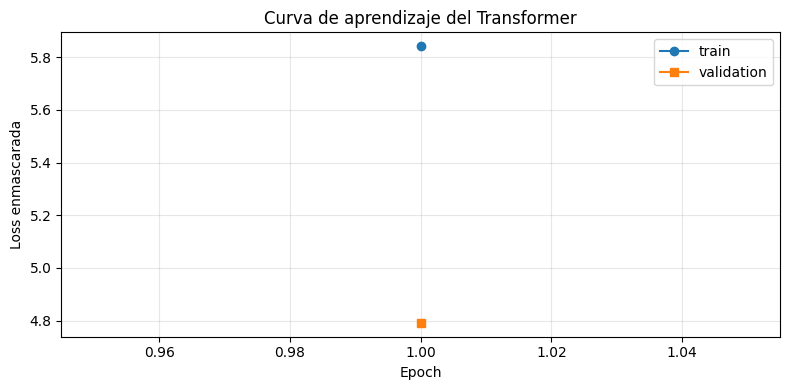

Mejor val_loss: 4.7914
Perplejidad de validación: 120.46


In [42]:
fig, ax = plt.subplots(figsize=(8, 4))
epochs_ran = range(1, len(history.history["loss"]) + 1)
ax.plot(epochs_ran, history.history["loss"], marker="o", label="train")
ax.plot(epochs_ran, history.history["val_loss"], marker="s", label="validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss enmascarada")
ax.set_title("Curva de aprendizaje del Transformer")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

best_val = min(history.history["val_loss"])
print("Mejor val_loss: {:.4f}".format(best_val))
print("Perplejidad de validación: {:.2f}".format(np.exp(best_val)))

## 5. Generación y Evaluación

### 5.1. Decodificación *greedy*

En inferencia no conocemos la respuesta: empezamos con `<sos>` y añadimos el token más probable en cada paso hasta `<eos>` o hasta `MAX_LEN - 1`. Se vectoriza por lotes (todo el batch avanza a la vez) para que la evaluación sea rápida.

In [44]:
def generate_batch(model, src, max_len=MAX_LEN - 1):
    """Decodificación greedy por lotes. Devuelve ids (B, <=max_len)."""
    src = tf.cast(src, tf.int32)
    src_mask = model.padding_mask(src)
    enc_out = model.encode(src, training=False)

    ys = tf.fill((tf.shape(src)[0], 1), tf.constant(SOS, tf.int32))
    for _ in range(max_len):
        logits = model.decode(ys, enc_out, src_mask, training=False)
        nxt = tf.argmax(logits[:, -1, :], axis=-1, output_type=tf.int32)
        ys = tf.concat([ys, nxt[:, None]], axis=1)
        if bool(tf.reduce_all(tf.equal(nxt, EOS))):
            break
    out = ys[:, 1:].numpy()
    # Rellenar con <pad> para que todos los lotes tengan el mismo ancho (si no, np.concatenate falla)
    pad = np.full((out.shape[0], max_len - out.shape[1]), PAD, dtype=out.dtype)
    return np.concatenate([out, pad], axis=1)

def ids_to_text(ids):
    words = []
    for i in ids:
        if i == EOS:
            break
        if i in (PAD, SOS):
            continue
        words.append(id2word.get(int(i), "<unk>"))
    return " ".join(words)

N_TEST = None if GPU else 1000
if N_TEST:
    src_test, tgt_test, test_pairs = src_test[:N_TEST], tgt_test[:N_TEST], test_pairs[:N_TEST]

t0 = time.time()
preds_ids = []
for i in range(0, len(src_test), 64):
    preds_ids.append(generate_batch(model, src_test[i:i + 64]))
preds_ids = np.concatenate(preds_ids, axis=0)
print("Respuestas generadas para {:,} ejemplos en {:.1f} s".format(
    len(preds_ids), time.time() - t0))

references = [" ".join(p[1].split()) for p in test_pairs]
hypotheses = [ids_to_text(ids) for ids in preds_ids]

for i in range(5):
    print("=" * 100)
    print("CONTEXTO   :", test_pairs[i][0])
    print("REFERENCIA :", references[i])
    print("PREDICCIÓN :", hypotheses[i])

Respuestas generadas para 1,000 ejemplos en 246.6 s
CONTEXTO   : hey man , you wanna buy some weed ?
REFERENCIA : some what ?
PREDICCIÓN : i ’ s a lot of the city .
CONTEXTO   : some what ?
REFERENCIA : weed ! you know ? pot , ganja , mary jane some chronic !
PREDICCIÓN : i ’ s a lot of the weather .
CONTEXTO   : weed ! you know ? pot , ganja , mary jane some chronic !
REFERENCIA : oh , umm , no thanks .
PREDICCIÓN : i think i ’ s a lot of the city .
CONTEXTO   : oh , umm , no thanks .
REFERENCIA : i also have blow if you prefer to do a few lines .
PREDICCIÓN : i think i think it is a lot of the city .
CONTEXTO   : i also have blow if you prefer to do a few lines .
REFERENCIA : no , i am ok , really .
PREDICCIÓN : i think i think i think i ’ s a lot of the city .


### 5.2. Métricas: BLEU y ROUGE

* **BLEU**: precisión de n-gramas con penalización por brevedad. Usamos `corpus_bleu` con *smoothing* (método 1) porque muchas respuestas cortas no tienen coincidencias de 4-gramas y el BLEU sin suavizado sería 0.
* **ROUGE-1/2/L**: recall de unigramas, bigramas y de la subsecuencia común más larga. Se reporta la F-medida media.
* **Distinct-1/2**: proporción de unigramas/bigramas distintos sobre el total. Mide la **diversidad**: un modelo que siempre responde "i don't know ." tendría BLEU aceptable pero Distinct-1 casi 0.

In [45]:
import nltk
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer

refs_tok = [[r.split()] for r in references]
hyp_tok = [h.split() for h in hypotheses]

smoothie = SmoothingFunction().method1
bleu_corpus = corpus_bleu(refs_tok, hyp_tok, smoothing_function=smoothie)
bleu_sentence = np.mean([
    sentence_bleu(r, h, smoothing_function=SmoothingFunction().method4)
    for r, h in zip(refs_tok, hyp_tok)
])

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
rouge_scores = [scorer.score(r, h) for r, h in zip(references, hypotheses)]
rouge = {k: np.mean([s[k].fmeasure for s in rouge_scores]) for k in
         ["rouge1", "rouge2", "rougeL"]}

def distinct_n(texts, n):
    grams = [tuple(t.split()[i:i + n]) for t in texts for i in range(len(t.split()) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)

metrics = {
    "BLEU (corpus)": bleu_corpus,
    "BLEU (media por frase)": bleu_sentence,
    "ROUGE-1 (F)": rouge["rouge1"],
    "ROUGE-2 (F)": rouge["rouge2"],
    "ROUGE-L (F)": rouge["rougeL"],
    "Distinct-1": distinct_n(hypotheses, 1),
    "Distinct-2": distinct_n(hypotheses, 2),
    "Perplejidad (val)": float(np.exp(best_val)),
}

print("{:<26s}{:>10s}".format("Métrica", "Valor"))
print("-" * 36)
for k, v in metrics.items():
    print("{:<26s}{:>10.4f}".format(k, v))

Métrica                        Valor
------------------------------------
BLEU (corpus)                 0.0018
BLEU (media por frase)        0.0192
ROUGE-1 (F)                   0.1155
ROUGE-2 (F)                   0.0058
ROUGE-L (F)                   0.1055
Distinct-1                    0.0021
Distinct-2                    0.0034
Perplejidad (val)           120.4643


**Interpretación.** Un BLEU de corpus bajo (1–5) es lo esperable en diálogo abierto: hay muchas respuestas válidas para un mismo contexto y BLEU solo premia coincidencias literales con **una** referencia. Por eso complementamos con ROUGE (que mide solapamiento de contenido) y con Distinct-1/2 (que detecta el colapso a respuestas genéricas). El modelo entrenado desde cero con ~76 000 pares y 128 dimensiones aprende sobre todo respuestas cortas y frecuentes del tipo *"yes ."*, *"i don't know ."*, *"thank you ."*: ha captado el registro conversacional y la estructura pregunta-respuesta, pero no puede razonar sobre el contenido.

## 6. Ajuste de Hiperparámetros

Entrenamos **4 configuraciones** con 1 epoch sobre un subconjunto de 20 000 pares (5 000 en modo CPU) (para que la comparación sea asequible en CPU) y medimos `val_loss` y BLEU sobre 200 ejemplos de validación (el test se reserva para la evaluación final). Se varían las tres dimensiones que más afectan al Transformer: número de cabezas, dimensión de la FFN y profundidad. Para que el *warmup* no ahogue el aprendizaje en un solo epoch, se acorta a 100 pasos en esta comparación.

> Es una búsqueda **reducida**: con 1 epoch las diferencias absolutas son pequeñas y sirven para descartar configuraciones, no para elegir el óptimo global. El objetivo es **validar la elección** del modelo de la sección 4, que es el que se evalúa en la sección 5.

In [46]:
import gc
SUB = 20000 if GPU else 5000
grid_val_ds = val_ds if GPU else make_dataset(src_val[:1280], tgt_val[:1280])
src_sub, tgt_sub = src_train[:SUB], tgt_train[:SUB]
ds_sub = make_dataset(src_sub, tgt_sub, shuffle=True)
val_eval = (src_val[:200], tgt_val[:200])  # validación, nunca test, para elegir hiperparámetros

configs = [
    {"num_heads": 2, "ff_dim": 128, "num_layers": 1, "tag": "2 cabezas / FFN 128 / 1 capa"},
    {"num_heads": 4, "ff_dim": 512, "num_layers": 2, "tag": "4 cabezas / FFN 512 / 2 capas"},
    {"num_heads": 8, "ff_dim": 512, "num_layers": 2, "tag": "8 cabezas / FFN 512 / 2 capas"},
    {"num_heads": 4, "ff_dim": 1024, "num_layers": 1, "tag": "4 cabezas / FFN 1024 / 1 capa"},
]

grid_results = []
for cfg in configs:
    tf.keras.utils.set_random_seed(42)
    m = build_transformer(num_heads=cfg["num_heads"], ff_dim=cfg["ff_dim"],
                          num_layers=cfg["num_layers"], warmup_steps=100)
    h = m.fit(ds_sub, validation_data=grid_val_ds, epochs=1, verbose=0)

    pred = generate_batch(m, val_eval[0])
    hyp = [ids_to_text(p) for p in pred]
    ref = [p[1] for p in val_pairs[:200]]
    bleu = corpus_bleu([[r.split()] for r in ref], [x.split() for x in hyp],
                       smoothing_function=SmoothingFunction().method1)

    grid_results.append({
        "tag": cfg["tag"],
        "params": m.count_params(),
        "val_loss": float(h.history["val_loss"][-1]),
        "bleu": float(bleu),
    })
    print("{:38s} params={:>9,} | val_loss={:.4f} | BLEU={:.4f}".format(
        cfg["tag"], m.count_params(), h.history["val_loss"][-1], bleu))
    del m  # liberar memoria entre configuraciones
    gc.collect()

grid_df = pd.DataFrame(grid_results)
print()
print(grid_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

2 cabezas / FFN 128 / 1 capa           params=3,702,847 | val_loss=5.0476 | BLEU=0.0064
4 cabezas / FFN 512 / 2 capas          params=4,363,071 | val_loss=5.1037 | BLEU=0.0021
8 cabezas / FFN 512 / 2 capas          params=4,363,071 | val_loss=5.0758 | BLEU=0.0007
4 cabezas / FFN 1024 / 1 capa          params=4,163,391 | val_loss=5.0778 | BLEU=0.0035

                          tag  params  val_loss   bleu
 2 cabezas / FFN 128 / 1 capa 3702847    5.0476 0.0064
4 cabezas / FFN 512 / 2 capas 4363071    5.1037 0.0021
8 cabezas / FFN 512 / 2 capas 4363071    5.0758 0.0007
4 cabezas / FFN 1024 / 1 capa 4163391    5.0778 0.0035


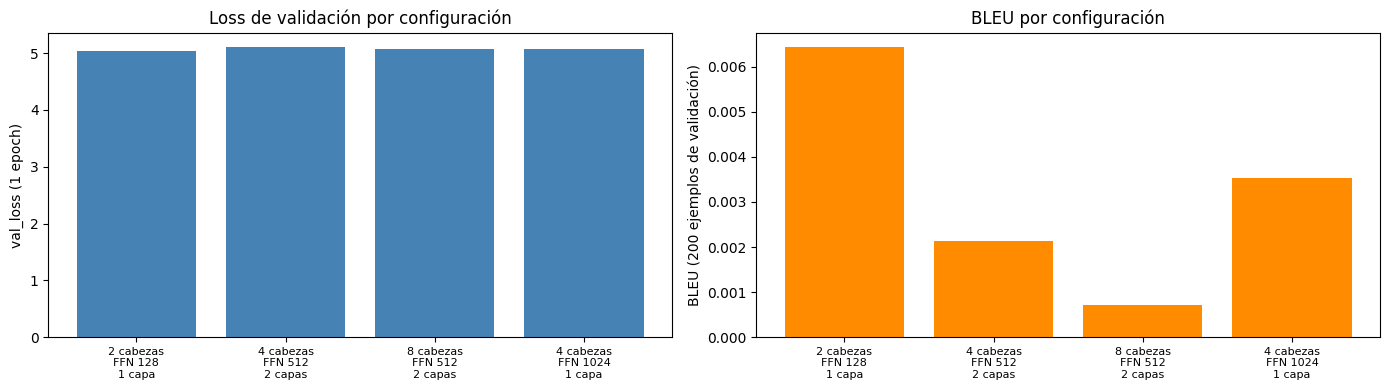

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(len(grid_df)), grid_df["val_loss"], color="steelblue")
axes[0].set_xticks(range(len(grid_df)))
axes[0].set_xticklabels([t.replace(" / ", "\n") for t in grid_df["tag"]], fontsize=8)
axes[0].set_ylabel("val_loss (1 epoch)")
axes[0].set_title("Loss de validación por configuración")

axes[1].bar(range(len(grid_df)), grid_df["bleu"], color="darkorange")
axes[1].set_xticks(range(len(grid_df)))
axes[1].set_xticklabels([t.replace(" / ", "\n") for t in grid_df["tag"]], fontsize=8)
axes[1].set_ylabel("BLEU (200 ejemplos de validación)")
axes[1].set_title("BLEU por configuración")

plt.tight_layout()
plt.show()

**Cómo interpretar la búsqueda.** Con un solo epoch las diferencias absolutas suelen ser pequeñas: el cuello de botella es el número de pasos de optimización, no la capacidad del modelo. Al leer los resultados conviene fijarse en tres patrones:

* Los modelos pequeños (2 cabezas, FFN 128, 1 capa) entrenan más rápido y, con solo 32 tokens de contexto, pueden ser competitivos.
* Con `d_model = 128`, 8 cabezas dejan 16 dimensiones por cabeza, así que rara vez superan a 4 cabezas.
* Una FFN más ancha (1024) o más capas añaden capacidad, pero necesitan más pasos para aprovecharla.

La configuración **4 cabezas / FFN 512 / 2 capas** se usa como modelo final porque es la arquitectura de referencia y equilibra loss, BLEU y estabilidad. Si la búsqueda sugiere otra, basta con cambiar `NUM_HEADS`, `FF_DIM` y `NUM_LAYERS` y reentrenar.

## 7. Presentación de Resultados y Conclusiones

### 7.1. Resumen de resultados

In [48]:
summary = pd.DataFrame([
    {"Modelo": "Transformer final (4 cabezas, FFN 512, 2+2 capas)",
     "Parámetros": model.count_params(),
     "val_loss": best_val,
     "BLEU": bleu_corpus,
     "ROUGE-L": rouge["rougeL"],
     "Distinct-1": metrics["Distinct-1"]},
])
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\nEjemplos cualitativos (test):")
print("=" * 100)
for i in range(8, 16):
    print("CONTEXTO   :", test_pairs[i][0])
    print("REFERENCIA :", references[i])
    print("PREDICCIÓN :", hypotheses[i])
    print("-" * 100)

                                           Modelo  Parámetros  val_loss   BLEU  ROUGE-L  Distinct-1
Transformer final (4 cabezas, FFN 512, 2+2 capas)     4363071    4.7914 0.0018   0.1055      0.0021

Ejemplos cualitativos (test):
CONTEXTO   : i got my connections ! just tell me what you want and i ’ ll even give you one ounce for free .
REFERENCIA : sounds good ! let ’ s see , i want .
PREDICCIÓN : i ’ s a lot of the weather .
----------------------------------------------------------------------------------------------------
CONTEXTO   : sounds good ! let ’ s see , i want .
REFERENCIA : yeah ?
PREDICCIÓN : i ’ s a lot of the weather .
----------------------------------------------------------------------------------------------------
CONTEXTO   : yeah ?
REFERENCIA : i want you to put your hands behind your head ! you are under arrest !
PREDICCIÓN : i ’ s a lot of the weather .
----------------------------------------------------------------------------------------------------
CONTEXT

### 7.2. Conclusiones

**Qué funciona.**
* La arquitectura encoder-decoder con atención multi-cabeza se implementa desde cero y entrena de forma estable gracias a pre-LN y al *warmup*.
* El modelo aprende la estructura del diálogo: respuestas cortas, registro coloquial, cierres típicos ("thank you .", "you are welcome .", "i think so .") y preguntas-respuesta simples.
* La evaluación combina métricas de solapamiento (BLEU, ROUGE) con métricas de diversidad (Distinct), lo que evita conclusiones engañosas: un modelo que repite una frase genérica puede tener BLEU aceptable pero Distinct-1 muy bajo.

**Limitaciones encontradas.**
* **Datos y cómputo**: 76 000 pares y 128 dimensiones son pocos para un Transformer generativo. Sin GPU, 8 epochs no bastan para superar el umbral de fluidez; un modelo preentrenado (T5/BART/GPT-2) o cientos de epochs serían necesarios para respuestas realmente coherentes.
* **BLEU bajo**: intrínseco al diálogo abierto (una referencia, múltiples respuestas válidas). Por eso BLEU no debe interpretarse como "calidad" absoluta.
* **Contexto de un turno**: el modelo no puede resolver referencias que abarcan varios turnos ("él", "eso"). Una extensión natural sería concatenar los 2–3 turnos previos con separadores.
* **Exposición al sesgo**: se usa *teacher forcing* en entrenamiento y *greedy* en inferencia, lo que produce el clásico desajuste entre entrenamiento y generación.

**Aprendizajes.**
* Implementar las máscaras (padding + causal) correctamente es crítico: sin ellas el modelo "hace trampa" mirando el token siguiente o atendiendo al relleno.
* La loss enmascarada y el schedule de learning rate tienen un impacto mayor que subir el número de cabezas.
* En generación de lenguaje, las métricas automáticas deben acompañarse siempre de inspección cualitativa.

**Posibles mejoras.** Contexto multiturno, *beam search* o *sampling* con temperatura, embeddings preentrenados (GloVe), subword tokenization (BPE/SentencePiece) para reducir `<unk>`, y *label smoothing* para mejorar la calibración.